## Embeddings: Node2Vec

- Se aprenden embeddings de los proveedores con **Node2Vec** sobre el subgrafo de co-participación de `a_grafo`

- Se elige la dimensión y se precalcula la **grilla de p y q** completa ("calcular una vez, explorar muchas")

- **SVD** de la adyacencia normalizada como referencia lineal

- **Local** (numpy + gensim): ver tabla de ejecución en `a_grafo`

### Constantes

- `RANGO_P`, `RANGO_Q`: parámetros de retorno y de entrada-salida de Node2Vec; 0.25 y 4 son extremos (16× de sesgo entre ellos): con 0.5-2 las configuraciones no se distinguían del ruido entre semillas

- `RANGO_DIM`: dimensiones del embedding que se comparan

- `N_PASEOS` = 10, `LARGO` = 40, `VENTANA` = 5, `EPOCAS` = 1: valores del artículo original (Grover & Leskovec, 2016) con un paseo más corto (40 en vez de 80): el grafo tiene diámetro chico y el costo crece lineal con el largo

- `K_NN` = 10: vecinos en el embedding con que se perfila cada configuración

- `N_MUESTRA` = 5,000: nodos sobre los que se miden los vecinos

- `SEMILLAS`: semillas para medir la estabilidad

In [1]:
RANGO_P = [0.25, 1.0, 4.0]
RANGO_Q = [0.25, 1.0, 4.0]
RANGO_DIM = [32, 64, 128]
N_PASEOS, LARGO, VENTANA, EPOCAS = 10, 40, 5, 1
K_NN = 10
N_MUESTRA = 5000
SEMILLAS = [42, 7]

### Detalle

| Configuración | Paseo | Qué acerca (Grover & Leskovec, 2016) |
|---|---|---|
| p = 1, q = 1 | Paseo aleatorio ponderado (DeepWalk) | Referencia |
| q > 1 (q = 4) | Tipo **BFS**: se queda en el vecindario inmediato del nodo previo | **Equivalencia estructural**: nodos con vecindarios parecidos (mismo **rol**) |
| q < 1 (q = 0.25) | Tipo **DFS**: se aleja y recorre el grupo | **Homofilia**: nodos de la misma comunidad o mercado |
| p chico (0.25) | Vuelve seguido al nodo previo | Paseo más local |
| p grande (4) | Evita volver | Explora más |

### Utilidades

In [2]:
NOTEBOOK = "b_node2vec"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- `nodos`, `aristas` y `aristas_anio` de `a_grafo`

- Tipología de KMeans (`02_Clustering`) solo para **describir** los vecinos; Node2Vec no la ve

In [4]:
nodos = pd.read_parquet(datos_dir / "nodos.parquet")
aristas = pd.read_parquet(datos_dir / "aristas.parquet")
aristas_anio = pd.read_parquet(datos_dir / "aristas_anio.parquet")
n = len(nodos)
A = matriz_adyacencia(aristas.i.to_numpy(), aristas.j.to_numpy(), aristas.peso.to_numpy(), n)
tip = tipologia_proveedor(nodos.clave)
rng = np.random.default_rng(SEED)
muestra = np.sort(rng.choice(n, N_MUESTRA, replace=False))
print(f"nodos: {n:,} | aristas: {len(aristas):,} | con tipología: {pd.notna(tip).sum():,}")

nodos: 56,975 | aristas: 1,383,731 | con tipología: 11,665


---
### **1. Costo**

Un embedding de referencia con p = q = 1 y 64 dimensiones (antes de elegir `DIM`): tiempo de los paseos, de Word2Vec y memoria de los paseos

In [5]:
E_ref, t_ref = node2vec(A, 1.0, 1.0, 64, N_PASEOS, LARGO, VENTANA, EPOCAS)
costo = pd.DataFrame([("nodos", n), ("paseos", n * N_PASEOS), ("tokens (nodos visitados)", n * N_PASEOS * LARGO),
                      ("tiempo paseos (s)", t_ref["t_paseos_s"]), ("tiempo Word2Vec (s)", t_ref["t_w2v_s"]),
                      ("memoria de los paseos (MB)", t_ref["mb_paseos"])], columns=["medida", "valor"]).round(1)
costo

,medida,valor
0,nodos,56975.0
1,paseos,569750.0
2,tokens (nodos visitados),22790000.0
3,tiempo paseos (s),13.3
4,tiempo Word2Vec (s),128.6
5,memoria de los paseos (MB),91.2


- **57k nodos × 10 paseos × 40 pasos = 22.8M de tokens** por embedding

- Los paseos vectorizados toman ~15 s; **Word2Vec es el 90% del costo** (~150 s con un hilo)

- 91 MB de paseos en memoria: cabe de sobra en local

---
### **2. Dimensión `DIM`**

- **Criterio sin fuga:** embedding solo con el grafo de **2023**; se mide si separa los pares que **aparecen en 2024** de pares al azar

- Puntaje del par = coseno entre los dos embeddings (sin clasificador: solo la geometría del espacio)

- AUC = probabilidad de que un par nuevo real tenga mayor coseno que uno al azar

In [6]:
A23 = grafo_anios(aristas_anio, [2023], n)
act23 = np.flatnonzero(np.diff(A23.indptr) > 0)
pos24 = pares_nuevos(aristas_anio, 2024, A23, act23)
neg24 = negativos(A23, _llave(pos24[:, 0], pos24[:, 1], n), act23, len(pos24), 0.0, rng)
ii, jj = np.r_[pos24[:, 0], neg24[:, 0]], np.r_[pos24[:, 1], neg24[:, 1]]
y = np.r_[np.ones(len(pos24)), np.zeros(len(neg24))]
print(f"grafo 2023: {len(act23):,} nodos activos, {A23.nnz // 2:,} aristas | pares 2024: {len(pos24):,} positivos + {len(neg24):,} al azar")

dimension = []
for d in RANGO_DIM:
    E23, _, t = node2vec_activos(A23, 1.0, 1.0, d, n_paseos=N_PASEOS, largo=LARGO, ventana=VENTANA, epocas=EPOCAS)
    En = normalizar(E23)
    dimension.append({"dim": d, "auc_coseno": roc_auc_score(y, (En[ii] * En[jj]).sum(1)),
                      "tiempo_s": t["t_paseos_s"] + t["t_w2v_s"]})
dimension = pd.DataFrame(dimension).round(4)
dimension

grafo 2023: 30,632 nodos activos, 482,865 aristas | pares 2024: 213,179 positivos + 213,179 al azar


,dim,auc_coseno,tiempo_s
0,32,0.8787,61.6727
1,64,0.8615,67.5116
2,128,0.8531,81.2470


- **32 dimensiones dan el mejor AUC (0.879)**, sobre 64 (0.862) y 128 (0.853)

- Con ~31k nodos activos y paseos de 40 pasos, más dimensiones sobreajustan el ruido de co-participaciones esporádicas

- Se fija `DIM = 32`: mejor separación de los pares futuros y la mitad de memoria que 64

In [7]:
DIM = 32

---
### **3. Grilla p × q**

- Se entrena una vez cada combinación de `RANGO_P` × `RANGO_Q` sobre el subgrafo completo, con la misma semilla

- Cada embedding se guarda en `temp/datos/emb_p<p>_q<q>.npy`: los notebooks siguientes y la web solo los leen

In [8]:
nombre = lambda p, q: f"p{p:g}_q{q:g}"
grilla, embs = [], {}
for p in RANGO_P:
    for q in RANGO_Q:
        E, t = (E_ref, t_ref) if (p, q, DIM) == (1.0, 1.0, 64) else node2vec(A, p, q, DIM, N_PASEOS, LARGO, VENTANA, EPOCAS)
        embs[nombre(p, q)] = E
        np.save(datos_dir / f"emb_{nombre(p, q)}.npy", E)
        grilla.append({"config": nombre(p, q), "p": p, "q": q, "tiempo_s": round(t["t_paseos_s"] + t["t_w2v_s"], 1)})
grilla = pd.DataFrame(grilla)
grilla

,config,p,q,tiempo_s
0,p0.25_q0.25,0.25,0.25,134.3
1,p0.25_q1,0.25,1.00,159.5
2,p0.25_q4,0.25,4.00,190.8
3,p1_q0.25,1.00,0.25,138.0
4,p1_q1,1.00,1.00,123.4
5,p1_q4,1.00,4.00,132.3
6,p4_q0.25,4.00,0.25,138.4
7,p4_q1,4.00,1.00,127.2
8,p4_q4,4.00,4.00,131.5


#### a. SVD como embedder

Misma dimensión; sin paseos ni p, q

In [9]:
t0 = time.time()
embs["svd"] = embedding_svd(A, DIM)
np.save(datos_dir / "emb_svd.npy", embs["svd"])
print(f"SVD: {time.time() - t0:.1f} s")

SVD: 2.3 s


---
### **4. Qué captura cada configuración**

- Para cada nodo de la muestra, sus `K_NN` vecinos más cercanos en el embedding

- **Al azar:** lo mismo con vecinos sorteados; es la línea base de cada columna

In [10]:
NN = {c: vecinos_emb(E, muestra, K_NN) for c, E in embs.items()}
NN["al azar"] = rng.choice(n, (N_MUESTRA, K_NN))
perfil = pd.DataFrame({c: perfil_vecindad(m, muestra, A, nodos, tip) for c, m in NN.items()}).T
perfil.index.name = "config"
perfil.round(3)

,% vecinos en el grafo,% misma región,% misma familia,% mismo segmento,% misma tipología,rol (Spearman grado)
config,,,,,,
p0.25_q0.25,27.674,61.428,53.951,69.670,67.073,0.813
p0.25_q1,27.460,60.022,54.243,70.090,66.485,0.814
p0.25_q4,27.378,59.332,54.003,69.824,66.758,0.820
p1_q0.25,27.488,61.548,53.869,69.771,66.542,0.802
p1_q1,27.432,60.298,54.017,69.899,66.904,0.817
p1_q4,27.150,59.006,54.177,70.000,68.908,0.830
p4_q0.25,27.608,61.906,53.841,69.547,67.004,0.798
p4_q1,27.500,60.534,54.144,69.986,66.934,0.822
p4_q4,26.904,59.136,54.236,70.082,67.083,0.834


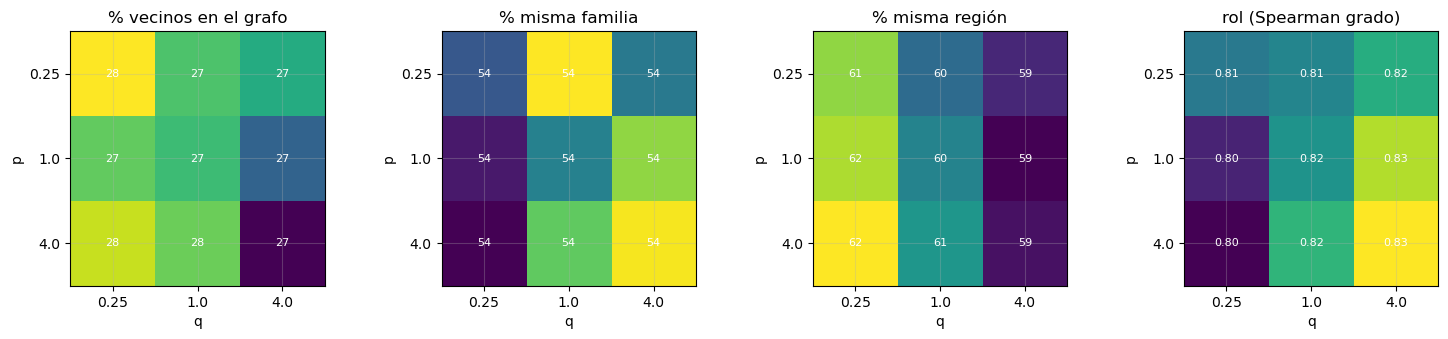

In [11]:
pq_ = perfil.loc[[nombre(p, q) for p in RANGO_P for q in RANGO_Q]]
cols = ["% vecinos en el grafo", "% misma familia", "% misma región", "rol (Spearman grado)"]
fig, ax = plt.subplots(1, len(cols), figsize=(15, 3.4))
for k_, c in enumerate(cols):
    M = pq_[c].to_numpy().reshape(len(RANGO_P), len(RANGO_Q))
    im = ax[k_].imshow(M, cmap="viridis")
    ax[k_].set(xticks=range(len(RANGO_Q)), xticklabels=RANGO_Q, yticks=range(len(RANGO_P)), yticklabels=RANGO_P,
               xlabel="q", ylabel="p", title=c)
    for (r_, s_), val in np.ndenumerate(M):
        ax[k_].text(s_, r_, f"{val:.2f}" if "rol" in c else f"{val:.0f}", ha="center", va="center", color="w", fontsize=8)
mostrar_fig("perfil_pq")

- **Todas las configuraciones capturan mercado:** ~60% de los vecinos son de la misma región (13% al azar) y ~54% de la misma familia UNSPSC (6% al azar)

- **Homofilia vs rol, en la dirección que predice la teoría:**

    - q = 0.25 (DFS) sube la homofilia regional (61.9% con p = 4) y baja el rol (0.80)

    - q = 4 (BFS) baja la región (59.0%) y sube el rol (0.83-0.83): vecinos con un grado parecido, aunque sean de otra región

- **Pero el efecto es chico:** ~3 puntos de región y 0.03 de rol entre los extremos (16× de sesgo)

- **Por qué:** cada proceso une a **todos** sus postores en un clique; el vecindario inmediato (BFS) y el mercado (DFS) casi coinciden

- **Rol alto en todas (≈ 0.8):** proveedores que ofertan mucho quedan cerca de otros que ofertan mucho; es en parte un efecto de frecuencia (Word2Vec ve más veces a los nodos de mayor grado)

- **SVD:** misma homofilia de rubro (53% familia) pero menos regional (57%) y **mucho menos rol (0.51)**: sin paseos no aprende posición estructural

---
### **5. Parecido entre configuraciones y estabilidad**

- **Jaccard de vecinos:** fracción de los `K_NN` vecinos que comparten dos configuraciones (1 = mismos vecinos)

- **Estabilidad:** misma configuración con otra semilla; si cambia mucho, los vecinos no son confiables

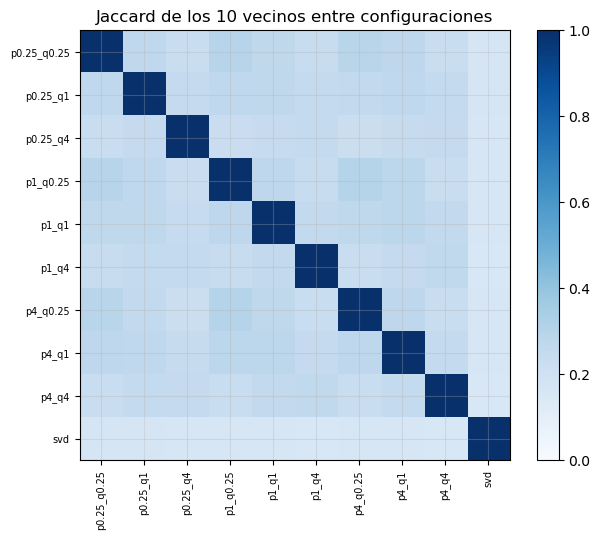

In [12]:
confs = list(embs)
similitud = pd.DataFrame([[jaccard_vecinos(NN[a_], NN[b_]) for b_ in confs] for a_ in confs], index=confs, columns=confs)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(similitud, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(confs)), xticklabels=confs, yticks=range(len(confs)), yticklabels=confs,
       title=f"Jaccard de los {K_NN} vecinos entre configuraciones")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7); plt.setp(ax.get_yticklabels(), fontsize=7)
plt.colorbar(im, ax=ax, fraction=.046)
mostrar_fig("similitud_configs")

In [13]:
E_s2, _ = node2vec(A, 1.0, 1.0, DIM, N_PASEOS, LARGO, VENTANA, EPOCAS, seed=SEMILLAS[1])
estabilidad = pd.DataFrame([
    ("Jaccard vecinos: semilla 42 vs 7 (p=1, q=1)", jaccard_vecinos(NN[nombre(1.0, 1.0)], vecinos_emb(E_s2, muestra, K_NN))),
    ("Jaccard vecinos: Node2Vec (1, 1) vs SVD", similitud.loc[nombre(1.0, 1.0), "svd"]),
    ("Jaccard vecinos: al azar vs Node2Vec (1, 1)", jaccard_vecinos(NN["al azar"], NN[nombre(1.0, 1.0)]))],
    columns=["medida", "valor"]).round(3)
estabilidad

,medida,valor
0,"Jaccard vecinos: semilla 42 vs 7 (p=1, q=1)",0.275
1,"Jaccard vecinos: Node2Vec (1, 1) vs SVD",0.163
2,"Jaccard vecinos: al azar vs Node2Vec (1, 1)",0.000


- **Entre configuraciones:** Jaccard de 0.23-0.30; **entre semillas** de la misma configuración: 0.28

- Cambiar p y q mueve los vecinos **lo mismo que cambiar la semilla**: las diferencias de p, q están en el orden del ruido de muestreo

- Lo estable es el **perfil agregado** (región, familia, rol), no la lista exacta de 10 vecinos: hay muchos proveedores casi equivalentes dentro de un mismo mercado

- **Node2Vec vs SVD:** comparten solo 16% de vecinos; el paseo y la factorización ven cosas distintas

---
### **6. Ejemplo: vecinos de un proveedor**

El proveedor con más procesos de la muestra y sus 5 vecinos en dos configuraciones opuestas

In [14]:
ej = muestra[np.argmax(nodos.n_procesos.to_numpy()[muestra])]
pos_ej = int(np.flatnonzero(muestra == ej)[0])
cols_ej = ["nombre", "region", "familia", "grado", "n_procesos", "n_ganados"]
ejemplo = pd.concat({c: nodos.iloc[NN[c][pos_ej, :5]][cols_ej].reset_index(drop=True)
                     for c in (nombre(0.25, 4.0), nombre(4.0, 0.25))})
print("Proveedor:", nodos.iloc[ej][cols_ej].to_dict())
ejemplo

Proveedor: {'nombre': 'ZARZOSA PRUDENCIO JORGE ARTURO', 'region': 'ANCASH', 'familia': '8110', 'grado': 2146, 'n_procesos': 2834, 'n_ganados': 19}


nombre  region  \
p0.25_q4 0                      POMA CASTILLO SERGIO ALEJANDRO  ANCASH   
         1                              MARQUEZ SANTIAGO ZENON  ANCASH   
         2                     ALVARADO SOLIS CELESTINO JAVIER  ANCASH   
         3                      MEJIA PALACIOS LORGIO EVARISTO  ANCASH   
         4  EMPRESA CONSULTORA Y CONSTRUCTORA LISOSAN E.I.R.L.  ANCASH   
p4_q0.25 0                      MEJIA PALACIOS LORGIO EVARISTO  ANCASH   
         1                       MENDOZA CADILLO ULISES ANIBAL  ANCASH   
         2  EMPRESA CONSULTORA Y CONSTRUCTORA LISOSAN E.I.R.L.  ANCASH   
         3                   SERVICIOS GENERALES YICS E.I.R.L.  ANCASH   
         4     EMPRESA CONSULTORA Y CONSTRUCTORA ECCSAM S.R.L.  ANCASH   

           familia  grado  n_procesos  n_ganados  
p0.25_q4 0    8110    101          83         13  
         1    8110    127          75          9  
         2    8110    249         225          9  
         3    8110    255         195          0  
         4    8110    149          90          2  
p4_q0.25 0    8110    255         195          0  
         1    8110   1164        1435          6  
         2    8110    149          90          2  
         3    8110     37          23          0  
         4    7212     68          47          2

- El proveedor con más procesos de la muestra es **Zarzosa Prudencio**, consultor de **ingeniería (8110) en Áncash**: 2,834 procesos y 19 adjudicaciones

- Con BFS (p = 0.25, q = 4) y con DFS (p = 4, q = 0.25), **9 de sus 10 vecinos son consultores 8110 de Áncash** con muchas ofertas y pocas adjudicaciones

- Las dos configuraciones comparten 2 de 5 vecinos, pero el perfil es el mismo: el mercado (rubro + región) domina sobre p y q

---
### **7. Escritura de resultados**

In [15]:
config = leer_config()
config.update({"dim": DIM, "rango_p": RANGO_P, "rango_q": RANGO_Q, "n_paseos": N_PASEOS, "largo": LARGO,
               "ventana": VENTANA, "epocas": EPOCAS, "configs": confs})
guardar_config(config)
escritos = guardar_tablas({"costo": costo, "dimension": dimension, "grilla": grilla,
                           "perfil_pq": perfil.reset_index(), "similitud": similitud.reset_index().rename(columns={"index": "config"}),
                           "estabilidad": estabilidad, "ejemplo_vecinos": ejemplo.reset_index(level=0).rename(columns={"level_0": "config"})})

Escrito en 06_Embeddings/temp/b_node2vec/: costo, dimension, grilla, perfil_pq, similitud, estabilidad, ejemplo_vecinos


#### a. Verificación

In [16]:
for c in confs:
    E = np.load(datos_dir / f"emb_{c}.npy")
    assert E.shape == (n, DIM) and np.isfinite(E).all() and (np.linalg.norm(E, axis=1) > 0).all(), c
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 2 figuras: perfil_pq, similitud_configs


---
### **8. Cerrar sesión**

In [17]:
spark.stop()